<a href="https://colab.research.google.com/github/Asmu26/LLM_AI/blob/main/Ecuador_IMF_Completed_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q pypdf

In [64]:
import os
import requests

pdf_path = "1ecuea2026001-source-pdf.pdf"

pdf_url =  "https://www.imf.org/-/media/files/publications/cr/2026/english/1ecuea2026001-source-pdf.pdf"

if not os.path.exists(pdf_path):
    response = requests.get(pdf_url, timeout=60)
    response.raise_for_status()

    with open(pdf_path, "wb") as f:
        f.write(response.content)

print("PDF ready:", pdf_path)

PDF ready: 1ecuea2026001-source-pdf.pdf


In [65]:

from pypdf import PdfReader

reader = PdfReader(pdf_path)

pages = []

for page_num, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""

    pages.append({
        "page": page_num,
        "text": text
    })

print("Total pages:", len(pages))
print("Total characters:", sum(len(p["text"]) for p in pages))

print("\nFirst page preview:")
print(pages[0]["text"][:1500])

Total pages: 114
Total characters: 322238

First page preview:
 
© 2026 International Monetary Fund 
IMF Country Report No. 26/84 
ECUADOR 
FIFTH REVIEW UNDER THE EXTENDED ARRANGEMENT 
UNDER THE EXTENDED FUND FACILITY, REQUESTS FOR 
WAIVERS OF NONOBSERVANCE OF PERFORMANCE 
CRITERIA, MODIFICATION OF PERFORMANCE 
CRITERIA, AND FINANCING ASSURANCES REVIEW—
PRESS RELEASE; STAFF REPORT; AND STATEMENT BY 
THE EXECUTIVE DIRECTOR FOR ECUADOR 
In the context of the Fifth Review Under the Extended Arrangement Under the Extended 
Fund Facility, the following documents have been released and are included in this 
package: 
 
• A Press Release including a statement by the Chair of the Executive Board. 
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s 
consideration on April 22, 2026, following discussions that ended on March 27, 2026, 
with the officials of Ecuador on economic developments and policies underpinning 
the IMF arrangement under the Extended Fund Facilit

In [66]:

import re

def clean_text(text):
    # Remove repeated IMF page headers and footers
    text = re.sub(
        r'(?im)^\s*INTERNATIONAL MONETARY FUND\s*$',
        '',
        text
    )

    text = re.sub(
        r'(?im)^\s*ECUADOR\s*$',
        '',
        text
    )

    # Remove standalone page numbers
    text = re.sub(r'(?m)^\s*\d{1,3}\s*$', '', text)

    # Remove excessive spaces and tabs
    text = re.sub(r'[ \t]+', ' ', text)

    # Join words broken across lines by hyphens
    text = re.sub(r'(\w)-\n(\w)', r'\1\2', text)

    # Replace single line breaks with spaces
    text = re.sub(r'(?<!\n)\n(?!\n)', ' ', text)

    # Reduce excessive blank lines
    text = re.sub(r'\n{3,}', '\n\n', text)

    return text.strip()

In [67]:

cleaned_pages = []

for page in pages:
    cleaned_pages.append({
        "page": page["page"],
        "text": clean_text(page["text"])
    })

cleaned_text = "\n\n".join(
    page["text"] for page in cleaned_pages
)

print("Original characters:",
      sum(len(p["text"]) for p in pages))

print("Cleaned characters:", len(cleaned_text))

print("\nCleaned text preview:\n")
print(cleaned_pages[0]["text"][:1500])

Original characters: 322238
Cleaned characters: 318450

Cleaned text preview:

© 2026 International Monetary Fund  IMF Country Report No. 26/84 

FIFTH REVIEW UNDER THE EXTENDED ARRANGEMENT  UNDER THE EXTENDED FUND FACILITY, REQUESTS FOR  WAIVERS OF NONOBSERVANCE OF PERFORMANCE  CRITERIA, MODIFICATION OF PERFORMANCE  CRITERIA, AND FINANCING ASSURANCES REVIEW— PRESS RELEASE; STAFF REPORT; AND STATEMENT BY  THE EXECUTIVE DIRECTOR FOR ECUADOR  In the context of the Fifth Review Under the Extended Arrangement Under the Extended  Fund Facility, the following documents have been released and are included in this  package:    • A Press Release including a statement by the Chair of the Executive Board.  • The Staff Report prepared by a staff team of the IMF for the Executive Board’s  consideration on April 22, 2026, following discussions that ended on March 27, 2026,  with the officials of Ecuador on economic developments and policies underpinning  the IMF arrangement under the Extended Fund F

In [68]:

!pip install -q tiktoken

import tiktoken

encoding = tiktoken.get_encoding("cl100k_base")

In [69]:

def chunk_text(text, chunk_size=400, overlap=50):
    tokens = encoding.encode(text)

    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(tokens), step):
        chunk_tokens = tokens[start:start + chunk_size]

        if not chunk_tokens:
            break

        chunks.append(
            encoding.decode(chunk_tokens)
        )

    return chunks

In [70]:

document_chunks = []

for page in cleaned_pages:
    page_chunks = chunk_text(page["text"])

    for chunk in page_chunks:
        document_chunks.append({
            "page": page["page"],
            "text": chunk,
            "token_count": len(encoding.encode(chunk))
        })

print("Total chunks:", len(document_chunks))

print("\nFirst chunk:")
print(document_chunks[0]["text"][:800])

print("\nFirst chunk token count:",
      document_chunks[0]["token_count"])

print("\nMaximum chunk size:",
      max(c["token_count"] for c in document_chunks))

Total chunks: 299

First chunk:
© 2026 International Monetary Fund  IMF Country Report No. 26/84 

FIFTH REVIEW UNDER THE EXTENDED ARRANGEMENT  UNDER THE EXTENDED FUND FACILITY, REQUESTS FOR  WAIVERS OF NONOBSERVANCE OF PERFORMANCE  CRITERIA, MODIFICATION OF PERFORMANCE  CRITERIA, AND FINANCING ASSURANCES REVIEW— PRESS RELEASE; STAFF REPORT; AND STATEMENT BY  THE EXECUTIVE DIRECTOR FOR ECUADOR  In the context of the Fifth Review Under the Extended Arrangement Under the Extended  Fund Facility, the following documents have been released and are included in this  package:    • A Press Release including a statement by the Chair of the Executive Board.  • The Staff Report prepared by a staff team of the IMF for the Executive Board’s  consideration on April 22, 2026, following discussions that ended on March 27, 2026,  with t

First chunk token count: 366

Maximum chunk size: 400


In [71]:

import pandas as pd

chunk_df = pd.DataFrame(document_chunks)

print("Chunk statistics:")
print(chunk_df["token_count"].describe())

print("\nChunks below 300 tokens:",
      (chunk_df["token_count"] < 300).sum())

print("\nChunks between 300 and 500 tokens:",
      chunk_df["token_count"].between(300, 500).sum())

print("\nChunks above 500 tokens:",
      (chunk_df["token_count"] > 500).sum())

Chunk statistics:
count    299.000000
mean     311.732441
std      128.439297
min        5.000000
25%      229.500000
50%      400.000000
75%      400.000000
max      400.000000
Name: token_count, dtype: float64

Chunks below 300 tokens: 96

Chunks between 300 and 500 tokens: 203

Chunks above 500 tokens: 0


In [72]:

# Tokenize pages and retain page references
all_tokens = []
token_pages = []

for page in cleaned_pages:
    tokens = encoding.encode(page["text"])

    all_tokens.extend(tokens)
    token_pages.extend([page["page"]] * len(tokens))

def improved_chunking(tokens, page_refs,
                      chunk_size=400, overlap=50):
    chunks = []
    step = chunk_size - overlap

    if len(tokens) != len(page_refs):
        raise ValueError("Token and page counts differ")

    for start in range(0, len(tokens), step):
        end = min(start + chunk_size, len(tokens))

        # Avoid a tiny final chunk
        if chunks and end - start < 300:
            break

        chunk_tokens = tokens[start:end]

        chunks.append({
            "chunk_id": len(chunks) + 1,
            "text": encoding.decode(chunk_tokens),
            "start_page": page_refs[start],
            "end_page": page_refs[end - 1],
            "token_count": len(chunk_tokens)
        })

        if end == len(tokens):
            break

    return chunks

improved_chunks = improved_chunking(
    all_tokens, token_pages
)

print("Total improved chunks:", len(improved_chunks))

Total improved chunks: 241


In [73]:

improved_df = pd.DataFrame(improved_chunks)

print(improved_df["token_count"].describe())

print("\nChunks below 300:",
      (improved_df["token_count"] < 300).sum())

print("Chunks between 300 and 500:",
      improved_df["token_count"].between(300, 500).sum())

print("Chunks above 500:",
      (improved_df["token_count"] > 500).sum())

# Check whether the last tokens are covered
last_chunk = improved_chunks[-1]
last_start = (len(improved_chunks) - 1) * 350
covered_until = last_start + last_chunk["token_count"]

print("\nTotal tokens:", len(all_tokens))
print("Tokens not covered:",
      len(all_tokens) - covered_until)

count    241.0
mean     400.0
std        0.0
min      400.0
25%      400.0
50%      400.0
75%      400.0
max      400.0
Name: token_count, dtype: float64

Chunks below 300: 0
Chunks between 300 and 500: 241
Chunks above 500: 0

Total tokens: 84414
Tokens not covered: 14


In [74]:

# Find the final token covered
last_start = (len(improved_chunks) - 1) * 350

# Replace the final chunk with all remaining tokens
final_tokens = all_tokens[last_start:]

improved_chunks[-1]["text"] = encoding.decode(final_tokens)
improved_chunks[-1]["token_count"] = len(final_tokens)
improved_chunks[-1]["end_page"] = token_pages[-1]

# Verify complete coverage
covered_until = last_start + len(final_tokens)

print("Total chunks:", len(improved_chunks))
print("Final chunk size:",
      improved_chunks[-1]["token_count"])
print("Tokens not covered:",
      len(all_tokens) - covered_until)

print("All chunks within 300–500 tokens:",
      all(300 <= c["token_count"] <= 500
          for c in improved_chunks))

Total chunks: 241
Final chunk size: 414
Tokens not covered: 0
All chunks within 300–500 tokens: True


In [75]:

from google import genai
from google.colab import userdata

client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY")
)

print("Gemini client configured successfully!")

Gemini client configured successfully!


In [76]:

from google.genai import types

# Select one chunk from the Ecuador IMF report
sample_chunk = improved_chunks[0]["text"]

prompt = f"""
You are a financial analyst reviewing an IMF Country Report
about Ecuador.

Summarise the following text in no more than 100 words.

Instructions:
1. Identify the main economic or financial findings.
2. Include numerical indicators only if explicitly stated.
3. Do not invent facts or figures.
4. Use clear, professional language.
5. If the text contains no substantive economic findings,
   state that clearly.

Source text:
{sample_chunk}
"""
response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=prompt,
    config=types.GenerateContentConfig(
        temperature=0.0
    )
)

print("=== TEST SUMMARY ===")
print(response.text)

=== TEST SUMMARY ===
Based on the provided text, there are no substantive economic findings. The source text exclusively contains administrative and procedural information regarding the release of documents for the Fifth Review Under the Extended Arrangement Under the Extended Fund Facility for Ecuador.


In [77]:

keywords = [
    "financial stability",
    "inflation",
    "banking sector",
    "economic growth",
    "financial risks"
]

matching_chunks = []

for chunk in improved_chunks:
    text_lower = chunk["text"].lower()

    matches = sum(
        keyword in text_lower
        for keyword in keywords
    )

    if matches >= 2:
        matching_chunks.append(chunk)

print("Matching chunks:", len(matching_chunks))

if matching_chunks:
    selected_chunk = matching_chunks[0]

    print("\nSource pages:",
          selected_chunk["start_page"],
          "-",
          selected_chunk["end_page"])

    print("\nSelected text:\n")
    print(selected_chunk["text"][:1500])


Matching chunks: 7

Source pages: 1 - 2

Selected text:

://www.imf.org 

Washington, D.C.    April 2026PR 26/126    The IMF Executive Board Concludes Fifth Review of the  Extended Fund Facility Arrangement for Ecuador  FOR IMMEDIATE RELEASE  • The IMF Executive Board completed the fifth review under Ecuador’s 48-month Extended  Fund Facility (EFF) arrangement, enabling an immediate disbursement of about US$400  million.  • Economic growth continues to exceed expectations amid low inflation; labor market  conditions are improving; and the current account continues to post sizable surpluses ,  supporting a sustained increase in international reserves to record-high levels.  • The authorities are making significant progress in the implementation of their economic  reform plan. Ecuador has successfully regained access to international capital markets.  The authorities adopted measures to address the fiscal underperformance of late 2025  and return to the program’s fiscal consolidation pat

In [78]:

financial_keywords = [
    "inflation",
    "gdp growth",
    "financial stability",
    "banking sector",
    "credit growth",
    "public debt",
    "economic outlook",
    "financial risks"
]

ranked_chunks = []

for chunk in improved_chunks:

    # Skip introductory pages
    if chunk["start_page"] <= 5:
        continue

    text_lower = chunk["text"].lower()

    score = sum(
        text_lower.count(keyword)
        for keyword in financial_keywords
    )

    if score > 0:
        ranked_chunks.append({
            "chunk": chunk,
            "score": score
        })

ranked_chunks.sort(
    key=lambda x: x["score"],
    reverse=True
)

print("Financial chunks found:", len(ranked_chunks))

for item in ranked_chunks[:5]:
    print(
        "Pages:",
        item["chunk"]["start_page"],
        "-",
        item["chunk"]["end_page"],
        "| Score:",
        item["score"]
    )


Financial chunks found: 69
Pages: 64 - 65 | Score: 8
Pages: 15 - 16 | Score: 6
Pages: 13 - 13 | Score: 5
Pages: 26 - 26 | Score: 5
Pages: 64 - 64 | Score: 5


In [79]:

selected_chunk = ranked_chunks[0]["chunk"]

print("Selected chunk ID:",
      selected_chunk["chunk_id"])

print("Source pages:",
      selected_chunk["start_page"],
      "-",
      selected_chunk["end_page"])

print("\nFinancial text:\n")
print(selected_chunk["text"])



Selected chunk ID: 158
Source pages: 64 - 65

Financial text:

.4 5.9 Source: Fund staff. Extended projectionMedium-term projection Contribution to Change in Public Debt (Percent of GDP) Commentary: Public debt would be on a downward path under the program. Projection -10 -5

2016 2018 2020 2022 2024 2026 2028 2030 2032 2034 2036

-7 -13

-24 -30 -50 -40 -30 -20 -10

Cumulative in the projection period Primary deficit Real Interest rate and relative inflation Real GDP growth Exch. rate depreciation Other flows Residual Change in public debtINTERNATIONAL MONETARY FUND 61  Figure 5. Ecuador: Realism of Baseline Assumptions      Forecast Track Record 1/ t+1 t+3 t+5 Comparator Group: Public debt to GDP Primary deficit r - g Color Code: Exchange rate depreciaton █ > 75th percentile SFA █ 50-75th percentile real-time t+3 t+5 █ 25-50th percentile Historical Output Gap Revisions 2/ █ < 25th percentile Public Debt Creating Flows Bond Issuances (Bars, debt issuances (RHS,  (Percent of GDP) %GDP)

In [80]:

# Find financial chunks containing narrative text
narrative_chunks = []

for item in ranked_chunks:
    chunk = item["chunk"]
    text = chunk["text"]

    # Prefer chunks containing complete sentences
    sentence_count = text.count(". ")

    # Avoid chunks dominated by numbers
    digit_ratio = sum(c.isdigit() for c in text) / max(len(text), 1)

    if sentence_count >= 4 and digit_ratio < 0.10:
        narrative_chunks.append(item)

print("Narrative financial chunks:", len(narrative_chunks))

for item in narrative_chunks[:5]:
    chunk = item["chunk"]

    print(
        "Chunk:", chunk["chunk_id"],
        "| Pages:", chunk["start_page"],
        "-", chunk["end_page"],
        "| Score:", item["score"]
    )


Narrative financial chunks: 56
Chunk: 158 | Pages: 64 - 65 | Score: 8
Chunk: 28 | Pages: 15 - 16 | Score: 6
Chunk: 22 | Pages: 13 - 13 | Score: 5
Chunk: 49 | Pages: 26 - 26 | Score: 5
Chunk: 62 | Pages: 33 - 34 | Score: 4


In [81]:

selected_chunk = narrative_chunks[0]["chunk"]

print("Selected chunk:", selected_chunk["chunk_id"])

print("Pages:",
      selected_chunk["start_page"],
      "-",
      selected_chunk["end_page"])

print("\nSource text:\n")
print(selected_chunk["text"])


Selected chunk: 158
Pages: 64 - 65

Source text:

.4 5.9 Source: Fund staff. Extended projectionMedium-term projection Contribution to Change in Public Debt (Percent of GDP) Commentary: Public debt would be on a downward path under the program. Projection -10 -5

2016 2018 2020 2022 2024 2026 2028 2030 2032 2034 2036

-7 -13

-24 -30 -50 -40 -30 -20 -10

Cumulative in the projection period Primary deficit Real Interest rate and relative inflation Real GDP growth Exch. rate depreciation Other flows Residual Change in public debtINTERNATIONAL MONETARY FUND 61  Figure 5. Ecuador: Realism of Baseline Assumptions      Forecast Track Record 1/ t+1 t+3 t+5 Comparator Group: Public debt to GDP Primary deficit r - g Color Code: Exchange rate depreciaton █ > 75th percentile SFA █ 50-75th percentile real-time t+3 t+5 █ 25-50th percentile Historical Output Gap Revisions 2/ █ < 25th percentile Public Debt Creating Flows Bond Issuances (Bars, debt issuances (RHS,  (Percent of GDP) %GDP); lines, avg 

In [82]:

selected_chunk = next(
    chunk for chunk in improved_chunks
    if chunk["chunk_id"] == 28
)

print("Selected chunk:", selected_chunk["chunk_id"])
print("Source pages:",
      selected_chunk["start_page"],
      "-",
      selected_chunk["end_page"])

print("\nSource text:\n")

print(selected_chunk["text"])


Selected chunk: 28
Source pages: 15 - 16

Source text:

 2025 with IMF TA, the authorities developed a new  methodology to operationalize it.  9 A referendum held in 2023 mandated the closure of the ITT oil field, accounting for about 12 percent of Ecuador’s  oil output. 

2025 2026 2027 2028 2029 2030 WTI Oil Price Projections (In US$ per barrel) Fourth Review Fifth Review Sources: Ministry of Economy and Finance and IMF World Economic Outlook. Note: Fifth Review prices from 2026 to 2030 reflect oil price assumptions from the  World Economic Outlook, April 2026.12 INTERNATIONAL MONETARY FUND    Box 1. Macroeconomic Impact of the Oil Price Shock  Oil prices rose sharply in March 2026 amid the conflict in the Middle East and disruptions to maritime flows  through the Strait of Hormuz. Since February 28, global oil prices have increased by over 40 percent, with  high volatility. For Ecuador, a net oil exporter, higher oil prices improve the terms of trade, strengthen the  external positi

In [83]:

selected_chunk = next(
    chunk for chunk in improved_chunks
    if chunk["chunk_id"] == 22
)

print("Selected chunk:", selected_chunk["chunk_id"])
print("Source pages:",
      selected_chunk["start_page"],
      "-",
      selected_chunk["end_page"])

print("\nSource text:\n")
print(selected_chunk["text"])


Selected chunk: 22
Source pages: 13 - 13

Source text:

ARY FUND 9  sector reaching 9.8 percent (y/y) in December 2025, driven by productive lending benefiting from  the gradual alignment of interest rates to market conditions in this segment. Robust deposit growth  of 15.5 percent (y/y) underpinned the credit recovery, bolstering system liquidity. In the private  banking sector, asset quality continued to improve, with nonperforming loan ratios declining,  provisioning coverage increasing, profitability recovering, and capital ratios remaining above the  regulatory minima. In the cooperative sector, financial soundness indicators remain highly  heterogeneous across institutions, underscoring  the need to continue monitoring the situation of  weaker institutions.  12. The security situation remains  challenging and geographically concentrated  in the coastal provinces. Homicides rose by 30  percent in 2025, remaining at a historically high  level. Homicides continue to be highly  conce

In [84]:

from google.genai import types

financial_prompt = f"""
You are a financial analyst examining an IMF
Staff Report on Ecuador.

TASK:
Summarise the financial and macroeconomic findings
in the provided source text.

INSTRUCTIONS:
1. Write fewer than 100 words.
2. Identify key economic developments.
3. Highlight financial strengths and risks.
4. Preserve numerical values and their dates.
5. Do not invent information.
6. Do not use information outside the source.
7. If evidence is insufficient, state this clearly.
8. Use professional, concise language.

SOURCE:
PDF pages {selected_chunk['start_page']}
to {selected_chunk['end_page']}

{selected_chunk['text']}
"""

response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=financial_prompt,
    config=types.GenerateContentConfig(
        temperature=0.0
    )
)

financial_summary = response.text

print("=== ECUADOR FINANCIAL SUMMARY ===")
print(financial_summary)

print("\nWord count:",
      len(financial_summary.split()))

=== ECUADOR FINANCIAL SUMMARY ===
Ecuador’s private banking sector showed improved asset quality, rising profitability, capital ratios above regulatory minima, and robust deposit growth of 15.5% (y/y). Productive lending drove private sector credit growth to 9.8% (y/y) by December 2025. Conversely, the cooperative sector displays heterogeneous financial soundness indicators, requiring ongoing monitoring. 

Real GDP growth is projected at 2.5% in 2026, rising to 3% medium-term. Inflation is expected to exceed 2% in 2026 before converging to 1.5%. The current account surplus is projected at a historically elevated 5.2% of GDP in 2026. Risks include a challenging, geographically concentrated security situation (homicides rose 30% in 2025).

Word count: 100


In [85]:

from google.genai import types

judge_prompt = f"""
You are an independent evaluator of
financial summaries.

Evaluate the generated summary against
the original IMF source text.

Score each criterion from 1 to 5:

1. Factual alignment:
Are all claims supported by the source?

2. Completeness:
Are the important financial findings included?

3. Consistency:
Are the numerical values, dates and
statements internally consistent?

Return:
- Factual alignment score
- Completeness score
- Consistency score
- Brief explanation of each score
- Any unsupported claims

SOURCE TEXT:
{selected_chunk['text']}

GENERATED SUMMARY:
{financial_summary}
"""

judge_response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=judge_prompt,
    config=types.GenerateContentConfig(
        temperature=0.0
    )
)

print("=== LLM JUDGE RESULTS ===")
print(judge_response.text)

=== LLM JUDGE RESULTS ===
Based on an evaluation of the generated summary against the original IMF source text, here are the scores and explanations:

### **Scores:**
* **Factual alignment score:** 5/5
* **Completeness score:** 4/5
* **Consistency score:** 5/5

---

### **Brief Explanation of Each Score:**

1. **Factual alignment (5/5):** 
   Every claim made in the generated summary is directly supported by the source text. The data points regarding credit growth (9.8%), deposit growth (15.5%), GDP projections (2.5% in 2026, 3% medium-term), inflation trends, current account surplus (5.2% of GDP), and the security situation (30% rise in homicides) are all accurately pulled from the source.

2. **Completeness (4/5):** 
   The summary captures the vast majority of the critical financial and economic findings from the source text, including banking sector health, GDP, inflation, current account projections, and security risks. However, it omits minor contextual details regarding the driv

In [86]:

import json

evaluation_result = {
    "country": "Ecuador",
    "report_year": 2026,
    "chunk_id": selected_chunk["chunk_id"],
    "source_pages": [
        selected_chunk["start_page"],
        selected_chunk["end_page"]
    ],
    "model": "gemini-3.5-flash-lite",
    "summary": financial_summary,
    "word_count": len(financial_summary.split()),
    "judge_model": "gemini-3.5-flash-lite",
    "judge_evaluation": judge_response.text
}

with open("ecuador_summary_evaluation.json", "w") as f:
    json.dump(evaluation_result, f, indent=4)

print("Evaluation saved successfully!")
print("File: ecuador_summary_evaluation.json")

Evaluation saved successfully!
File: ecuador_summary_evaluation.json


In [87]:

# Group chunks into batches
batch_size = 10

chunk_batches = [
    improved_chunks[i:i + batch_size]
    for i in range(0, len(improved_chunks), batch_size)
]

print("Total chunks:", len(improved_chunks))
print("Total batches:", len(chunk_batches))

for i, batch in enumerate(chunk_batches[:3]):
    print(
        f"Batch {i+1}:",
        f"{len(batch)} chunks,",
        f"pages {batch[0]['start_page']}"
        f"-{batch[-1]['end_page']}"
    )

Total chunks: 241
Total batches: 25
Batch 1: 10 chunks, pages 1-8
Batch 2: 10 chunks, pages 8-12
Batch 3: 10 chunks, pages 12-17


In [88]:

from google.genai import types

MODEL_NAME = "gemini-3.5-flash-lite"

def summarize_batch(batch, batch_number):
    source_text = "\n\n".join(
        f"[Chunk {c['chunk_id']}, "
        f"PDF pages {c['start_page']}-{c['end_page']}]\n"
        f"{c['text']}"
        for c in batch
    )

    prompt = f"""
You are a financial analyst reviewing the
2026 IMF Country Report on Ecuador.

Summarise the provided source material.

REQUIREMENTS:
1. Identify important macroeconomic developments.
2. Highlight financial stability findings and risks.
3. Preserve numerical values and dates accurately.
4. Do not invent facts or missing figures.
5. Ignore administrative and publication details.
6. Use concise bullet points.
7. Include PDF page references for each finding.
8. If a claim cannot be supported, omit it.
9. Limit the summary to 200 words.

SOURCE TEXT:
{source_text}
"""

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0.0
        )
    )

    if not response.text:
        raise ValueError("Empty Gemini response")

    return {
        "batch_number": batch_number,
        "start_page": batch[0]["start_page"],
        "end_page": batch[-1]["end_page"],
        "summary": response.text.strip()
    }

# Test only the first batch
test_batch_summary = summarize_batch(
    chunk_batches[0], 1
)

print("=== BATCH 1 SUMMARY ===")
print(test_batch_summary["summary"])

=== BATCH 1 SUMMARY ===
Here is a concise summary of the 2026 IMF Country Report on Ecuador:

* **Macroeconomic Developments:** Real GDP grew by 3.7% in 2025 and is projected to expand by 2.5% in 2026, driven by domestic demand and non-oil exports (PDF pp. 4, 5). Average inflation is projected at 2.9% in 2026 (PDF p. 4). Gross international reserves reached US$9.8 billion in 2025 and are projected at US$13.8 billion in 2026 (PDF p. 5). Public debt is projected at 52.7% of GDP in 2026 (PDF p. 5).
* **Capital Markets and Debt:** Ecuador re-entered international capital markets in January 2026 for the first time since 2019 via a US$4 billion bond issuance, which included a US$3 billion debt buy-back (PDF pp. 2, 7). 
* **Fiscal Position:** Fiscal targets missed expectations in late 2025, but authorities implemented corrective measures—such as streamlining tax expenditures and enhancing spending efficiency—to return to the consolidation path, projecting an overall fiscal deficit of 0.4% of 

In [89]:

import json
import time
import os

checkpoint_file = "ecuador_batch_summaries.json"

# Load previous results if available
if os.path.exists(checkpoint_file):
    with open(checkpoint_file, "r") as f:
        batch_summaries = json.load(f)
else:
    batch_summaries = []

completed_batches = {
    item["batch_number"] for item in batch_summaries
}

for i, batch in enumerate(chunk_batches, start=1):

    if i in completed_batches:
        print(f"Batch {i} already completed.")
        continue

    for attempt in range(3):
        try:
            result = summarize_batch(batch, i)
            batch_summaries.append(result)

            # Save after each successful batch
            with open(checkpoint_file, "w") as f:
                json.dump(batch_summaries, f, indent=4)

            print(f"Batch {i}/25 completed.")
            break

        except Exception as e:
            print(f"Batch {i}, attempt {attempt+1}: {e}")

            if attempt < 2:
                time.sleep(2 ** attempt)
            else:
                print(f"Batch {i} failed.")

    time.sleep(1)

batch_summaries.sort(
    key=lambda x: x["batch_number"]
)

print("\nCompleted batches:", len(batch_summaries))
print("Expected batches:", len(chunk_batches))

Batch 1 already completed.
Batch 2 already completed.
Batch 3 already completed.
Batch 4 already completed.
Batch 5 already completed.
Batch 6 already completed.
Batch 7 already completed.
Batch 8 already completed.
Batch 9 already completed.
Batch 10 already completed.
Batch 11 already completed.
Batch 12 already completed.
Batch 13 already completed.
Batch 14 already completed.
Batch 15 already completed.
Batch 16 already completed.
Batch 17 already completed.
Batch 18 already completed.
Batch 19 already completed.
Batch 20 already completed.
Batch 21 already completed.
Batch 22 already completed.
Batch 23 already completed.
Batch 24 already completed.
Batch 25 already completed.

Completed batches: 25
Expected batches: 25


In [90]:

print("Completed batches:", len(batch_summaries))
print("Expected batches:", len(chunk_batches))

completed_ids = {
    item["batch_number"] for item in batch_summaries
}

missing = [
    i for i in range(1, len(chunk_batches) + 1)
    if i not in completed_ids
]

print("Missing batches:", missing)
print("All batches complete:", len(missing) == 0)

Completed batches: 25
Expected batches: 25
Missing batches: []
All batches complete: True


In [91]:

from google.genai import types

# Combine all 25 batch summaries
combined_summaries = "\n\n".join(
    f"Batch {item['batch_number']} "
    f"(PDF pages {item['start_page']}-"
    f"{item['end_page']}):\n"
    f"{item['summary']}"
    for item in sorted(
        batch_summaries,
        key=lambda x: x["batch_number"]
    )
)

executive_prompt = f"""
You are a financial analyst preparing an executive
summary of the 2026 IMF Country Report on Ecuador.

Using ONLY the supplied batch summaries,
produce 6-8 concise bullet points covering:

1. Economic growth and outlook
2. Inflation and monetary conditions
3. Banking and financial stability
4. Public debt and fiscal sustainability
5. External sector developments
6. Economic strengths
7. Major vulnerabilities and risks
8. IMF policy recommendations

REQUIREMENTS:
- Preserve numerical values and dates accurately.
- Include PDF page references where available.
- Distinguish forecasts from historical observations.
- Do not invent missing information.
- Avoid repeating the same finding.
- If a topic is unsupported, omit it.

BATCH SUMMARIES:
{combined_summaries}
"""

executive_response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=executive_prompt,
    config=types.GenerateContentConfig(
        temperature=0.0
    )
)

executive_summary = executive_response.text.strip()

print("=== ECUADOR EXECUTIVE SUMMARY ===")
print(executive_summary)

=== ECUADOR EXECUTIVE SUMMARY ===
Here is the executive summary of the 2026 IMF Country Report on Ecuador, based strictly on the provided batch summaries:

* **Economic Growth and Outlook:** Real GDP grew by 3.7% in 2025, recovering strongly in the second half of the year from weather-related oil disruptions and an electricity crisis, and is projected to expand by 2.5% in 2026 (PDF pp. 4, 8–9, 68–69). Over the medium term, growth is expected to rise to 3.0% annually (PDF p. 13). 
* **Inflation and Monetary Conditions:** Inflation averaged 0.7% in 2025 (PDF pp. 8–9), while average inflation is projected at 2.9% in 2026 (PDF p. 5) (alternatively projected at 0.9% for the period average in 2026 [PDF p. 37]), with consumer price index inflation rising to 2.3% year-on-year in March 2026 due to base effects and normalized electricity prices (PDF pp. 8–9, 28, 112). Private sector credit grew by 9.8% year-on-year in December 2025 (PDF pp. 12–13), and broad money (M2) growth is projected at 5.3

In [92]:


import json

executive_result = {
    "country": "Ecuador",
    "report_year": 2026,
    "model": "gemini-3.5-flash-lite",
    "source_batches": len(batch_summaries),
    "executive_summary": executive_summary
}

with open("ecuador_executive_summary.json", "w") as f:
    json.dump(executive_result, f, indent=4)

print("Executive summary saved successfully!")
print("Source batches:", len(batch_summaries))

Executive summary saved successfully!
Source batches: 25


In [93]:

import re

section_headings = []

for page in cleaned_pages:
    page_number = page["page"]
    lines = page["text"].splitlines()

    for line in lines:
        heading = line.strip()

        if (
            5 <= len(heading) <= 100
            and heading.isupper()
            and re.search(r"[A-Z]{4,}", heading)
            and not re.search(r"\.{3,}", heading)
        ):
            section_headings.append({
                "page": page_number,
                "heading": heading
            })

print("Potential headings found:", len(section_headings))

for item in section_headings[:60]:
    print(f"Page {item['page']}: {item['heading']}")

Potential headings found: 5
Page 88: 4 INTERNATIONAL MONETARY FUND
Page 89: INTERNATIONAL MONETARY FUND 85    INTERNATIONAL MONETARY FUND 85
Page 90: 86 INTERNATIONAL MONETARY FUND
Page 91: INTERNATIONAL MONETARY FUND 87
Page 92: 88 INTERNATIONAL MONETARY FUND


In [94]:

from pypdf import PdfReader

reader = PdfReader(pdf_path)

# Examine the table of contents in the first 15 pages
for i in range(min(15, len(reader.pages))):
    text = reader.pages[i].extract_text(
        extraction_mode="layout"
    )

    if "CONTENTS" in text.upper():
        print(f"\n=== PDF PAGE {i+1} ===")
        print(text[:6000])


=== PDF PAGE 6 ===
ECUADOR


 Approved By                                  Discussions were held in Quito during February 26-March 6,
 Ana Corbacho (WHD) and                       2026      ,and remotely from           Washington DC during March 16     -
 Bergljot Barkbu (SPR)                        27. The team   ,led by   Patrizia Tumbarello (Head)   and Pablo
                                              Morra (Deputy Head),comprise   dMauricio Amaya,     Roberto
                                              Perrelli, Yiqun Wu (all WHD), Juan Carlos Benitez (FAD), Ivana
                                              Rossi (LEG), Joao Marques (MCM), andMahamoud Islam
                                              (SPR).Carlos Caceres (Resident Representative), Cristina
                                              Carrera, and Paola Hidalgo (all Resident Representative
                                              Office)participate  din the mission    . Mr. Morra led    a tech nical


In [95]:

import re

major_sections = [
    "CONTEXT",
    "RECENT MACROECONOMIC DEVELOPMENTS",
    "OUTLOOK AND RISKS",
    "POLICY DISCUSSIONS",
    "PROGRAM MODALITIES",
    "STAFF APPRAISAL"
]

section_locations = {}

for i in range(7, len(reader.pages)):
    text = reader.pages[i].extract_text() or ""

    for section in major_sections:
        if section in section_locations:
            continue

        # Find headings appearing on their own line
        pattern = rf"(?m)^\s*{re.escape(section)}\s*$"

        if re.search(pattern, text, re.IGNORECASE):
            section_locations[section] = i + 1

print("=== SECTION LOCATIONS ===")

for section in major_sections:
    print(
        section,
        "-> PDF page",
        section_locations.get(section, "Not found")
    )

=== SECTION LOCATIONS ===
CONTEXT -> PDF page 8
RECENT MACROECONOMIC DEVELOPMENTS -> PDF page Not found
OUTLOOK AND RISKS -> PDF page 13
POLICY DISCUSSIONS -> PDF page 14
PROGRAM MODALITIES -> PDF page 21
STAFF APPRAISAL -> PDF page 26


In [96]:

print("=== VERIFIED SECTION LOCATIONS ===")

for section in major_sections:
    page = section_locations.get(section)

    print(f"{section}: {page}")

# Check section order
pages = [
    section_locations.get(section)
    for section in major_sections
]

if all(page is not None for page in pages):
    print("\nSections in correct order:",
          pages == sorted(pages))
else:
    print("\nSome sections were not found.")

=== VERIFIED SECTION LOCATIONS ===
CONTEXT: 8
RECENT MACROECONOMIC DEVELOPMENTS: None
OUTLOOK AND RISKS: 13
POLICY DISCUSSIONS: 14
PROGRAM MODALITIES: 21
STAFF APPRAISAL: 26

Some sections were not found.


In [97]:

import re
import json
import time
from google.genai import types

# =====================================
# 1. DEFINE THE SIX MAJOR SECTIONS
# =====================================

major_sections = [
    "CONTEXT",
    "RECENT MACROECONOMIC DEVELOPMENTS",
    "OUTLOOK AND RISKS",
    "POLICY DISCUSSIONS",
    "PROGRAM MODALITIES",
    "STAFF APPRAISAL"
]

# =====================================
# 2. FIND SECTION LOCATIONS
# =====================================

section_locations = {}

# Search actual report pages, not contents
for i in range(7, len(reader.pages)):

    text = reader.pages[i].extract_text() or ""

    for section in major_sections:

        if section in section_locations:
            continue

        # Allow spaces and line breaks
        words = section.split()
        pattern = r"\s+".join(
            re.escape(word) for word in words
        )

        matches = list(
            re.finditer(pattern, text, re.IGNORECASE)
        )

        for match in matches:
            # Prefer heading-like occurrences
            line_start = text.rfind("\n", 0, match.start()) + 1
            line_end = text.find("\n", match.end())

            if line_end == -1:
                line_end = len(text)

            line = text[line_start:line_end].strip()

            if len(line) <= 120:
                section_locations[section] = i + 1
                break

print("=== SECTION LOCATIONS ===")

for section in major_sections:
    print(section, ":", section_locations.get(section))

# =====================================
# 3. CHECK SECTION LOCATIONS
# =====================================

missing = [
    section for section in major_sections
    if section not in section_locations
]

if missing:
    raise ValueError(
        f"Sections still missing: {missing}"
    )

positions = [
    section_locations[s] for s in major_sections
]

if positions != sorted(positions):
    raise ValueError(
        "Section pages are not in order. "
        "Inspect section_locations before summarising."
    )

# =====================================
# 4. GENERATE CHAPTER SUMMARIES
# =====================================

chapter_summaries = []

for i, section in enumerate(major_sections):

    start_page = section_locations[section]

    if i + 1 < len(major_sections):
        end_page = section_locations[
            major_sections[i + 1]
        ]
    else:
        end_page = min(
            start_page + 12,
            len(reader.pages) + 1
        )

    section_text = "\n".join(
        reader.pages[p - 1].extract_text() or ""
        for p in range(start_page, end_page)
    )

    prompt = f"""
You are analysing the Ecuador 2026 IMF report.

Summarise the following section.

SECTION: {section}

RULES:
1. Write fewer than 100 words.
2. Focus on key economic findings.
3. Include relevant financial risks.
4. Preserve numerical values accurately.
5. Do not invent information.
6. Use only the provided source text.
7. Return only the summary.

SOURCE TEXT:
{section_text[:35000]}
"""

    summary = None

    for attempt in range(3):

        try:
            response = client.models.generate_content(
                model="gemini-3.5-flash-lite",
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0.0
                )
            )

            summary = response.text.strip()
            break

        except Exception as e:
            print(
                f"{section}: attempt {attempt + 1} failed"
            )
            print(str(e)[:200])

            if attempt < 2:
                time.sleep(2 ** (attempt + 1))

    # Enforce fewer than 100 words
    if summary and len(summary.split()) >= 100:
        summary = " ".join(summary.split()[:99])

    result = {
        "section": section,
        "start_page": start_page,
        "end_page": end_page - 1,
        "summary": summary,
        "word_count": (
            len(summary.split()) if summary else 0
        )
    }

    chapter_summaries.append(result)

    print(
        f"{section}: {result['word_count']} words"
    )

    # Save after every chapter
    with open(
        "ecuador_chapter_summaries.json", "w"
    ) as f:
        json.dump(
            chapter_summaries,
            f,
            indent=4
        )

print("\n=== FINAL RESULTS ===")

print("Total sections:", len(chapter_summaries))

print(
    "Successfully summarised:",
    sum(
        item["summary"] is not None
        for item in chapter_summaries
    )
)

print("Saved: ecuador_chapter_summaries.json")

=== SECTION LOCATIONS ===
CONTEXT : 8
RECENT MACROECONOMIC DEVELOPMENTS : 8
OUTLOOK AND RISKS : 13
POLICY DISCUSSIONS : 14
PROGRAM MODALITIES : 21
STAFF APPRAISAL : 26
CONTEXT: 23 words
RECENT MACROECONOMIC DEVELOPMENTS: 88 words
OUTLOOK AND RISKS: 85 words
POLICY DISCUSSIONS: 70 words
PROGRAM MODALITIES: 84 words
STAFF APPRAISAL: 92 words

=== FINAL RESULTS ===
Total sections: 6
Successfully summarised: 6
Saved: ecuador_chapter_summaries.json


In [98]:

import re
import json
import pandas as pd

# Seven required financial stability themes
theme_keywords = {
    "Inflation & Prices": [
        "inflation", "consumer prices",
        "price stability", "cost of living"
    ],
    "Interest Rates & Credit": [
        "interest rate", "credit growth",
        "lending", "monetary policy"
    ],
    "Housing & Real Estate": [
        "housing", "real estate",
        "property market", "mortgage"
    ],
    "Banking Capital & Liquidity": [
        "bank capital", "capital adequacy",
        "liquidity", "banking sector"
    ],
    "Sovereign Debt": [
        "public debt", "sovereign debt",
        "government debt", "debt sustainability"
    ],
    "Labor Market Dynamics": [
        "unemployment", "employment",
        "labor market", "wages"
    ],
    "Systemic Financial Risk": [
        "financial stability", "systemic risk",
        "financial vulnerabilities",
        "stress testing"
    ]
}

theme_counts = {}

for theme, keywords in theme_keywords.items():
    total = 0

    for page in cleaned_pages:
        text = page["text"].lower()

        for keyword in keywords:
            pattern = (
                r"\b" + re.escape(keyword) + r"\b"
            )
            total += len(re.findall(pattern, text))

    theme_counts[theme] = total

theme_df = pd.DataFrame(
    list(theme_counts.items()),
    columns=["Theme", "Count"]
)

theme_df["Percentage"] = (
    theme_df["Count"]
    / theme_df["Count"].sum()
    * 100
).round(2)

theme_df = theme_df.sort_values(
    "Count", ascending=False
)

print("=== ECUADOR THEMATIC DISTRIBUTION ===")
print(theme_df.to_string(index=False))

with open("ecuador_theme_counts.json", "w") as f:
    json.dump(theme_counts, f, indent=4)

print("\nSaved: ecuador_theme_counts.json")

=== ECUADOR THEMATIC DISTRIBUTION ===
                      Theme  Count  Percentage
             Sovereign Debt     65       23.64
    Interest Rates & Credit     53       19.27
Banking Capital & Liquidity     51       18.55
      Labor Market Dynamics     48       17.45
         Inflation & Prices     40       14.55
    Systemic Financial Risk     15        5.45
      Housing & Real Estate      3        1.09

Saved: ecuador_theme_counts.json


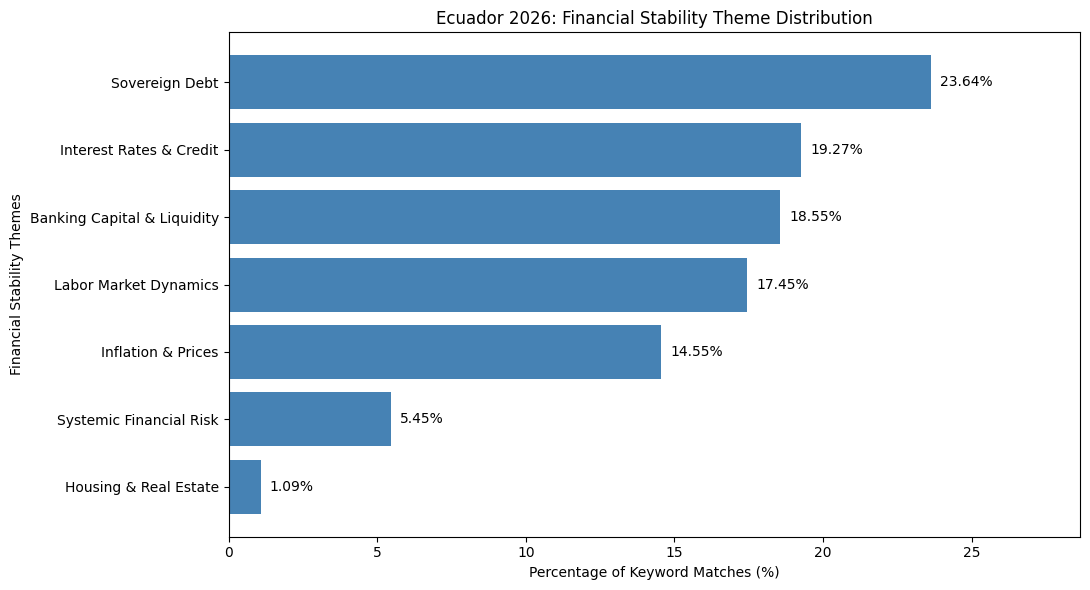

Chart saved successfully!


In [99]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

bars = plt.barh(
    theme_df["Theme"],
    theme_df["Percentage"],
    color="steelblue"
)

plt.xlabel("Percentage of Keyword Matches (%)")
plt.ylabel("Financial Stability Themes")
plt.title("Ecuador 2026: Financial Stability Theme Distribution")

plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.xlim(0, theme_df["Percentage"].max() + 5)
plt.tight_layout()

plt.savefig(
    "ecuador_theme_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

In [100]:

# Step 21: Validate theme distribution

total_matches = theme_df["Count"].sum()
total_percentage = theme_df["Percentage"].sum()

print("=== THEME VALIDATION ===")
print("Total keyword matches:", total_matches)
print("Total percentage:", round(total_percentage, 2))

print("\nTop 3 themes:")
print(
    theme_df.nlargest(3, "Count")[
        ["Theme", "Count", "Percentage"]
    ].to_string(index=False)
)

print("\nMissing values:")
print(theme_df.isnull().sum())

print("\nValidation complete!")

=== THEME VALIDATION ===
Total keyword matches: 275
Total percentage: 100.0

Top 3 themes:
                      Theme  Count  Percentage
             Sovereign Debt     65       23.64
    Interest Rates & Credit     53       19.27
Banking Capital & Liquidity     51       18.55

Missing values:
Theme         0
Count         0
Percentage    0
dtype: int64

Validation complete!


In [101]:

import re
import pandas as pd

# Search extracted PDF pages for economic indicators
indicator_patterns = {
    "GDP Growth": r"(?:real\s+)?GDP.{0,100}",
    "Inflation": r"inflation.{0,100}",
    "Public Debt": r"(?:public|government)\s+debt.{0,100}",
    "Fiscal Balance": r"fiscal\s+balance.{0,100}",
    "Credit Growth": r"(?:private\s+sector\s+)?credit\s+growth.{0,100}",
    "Current Account": r"current\s+account.{0,100}"
}

indicator_results = []

for page_num, page in enumerate(cleaned_pages, start=1):
    text = page["text"]

    for indicator, pattern in indicator_patterns.items():
        matches = re.finditer(
            pattern, text, flags=re.IGNORECASE
        )

        for match in matches:
            indicator_results.append({
                "Indicator": indicator,
                "PDF_Page": page_num,
                "Extracted_Text": match.group().strip()
            })

indicator_df = pd.DataFrame(indicator_results)

print("Total indicator mentions:", len(indicator_df))
print("\nMentions by indicator:")
print(indicator_df["Indicator"].value_counts())

display(indicator_df.head(15))

indicator_df.to_csv(
    "ecuador_indicator_mentions.csv",
    index=False
)

Total indicator mentions: 244

Mentions by indicator:
Indicator
GDP Growth         122
Public Debt         43
Inflation           37
Current Account     21
Credit Growth       13
Fiscal Balance       8
Name: count, dtype: int64


,Indicator,PDF_Page,Extracted_Text
0,GDP Growth,2,"Real GDP rebounded strongly in 2025 amid low inflation, labor market outcomes are improving, and ample liqu"
1,Inflation,2,inflation; labor market conditions are improving; and the current account continues to post sizable surpluse
2,Inflation,2,"inflation, labor market outcomes are improving, and ample liquidity in the financial system has supported st"
3,Credit Growth,2,"credit growth. The current account balance continues to record sizable surpluses, contributing to a sustained r"
4,Current Account,2,"current account continues to post sizable surpluses , supporting a sustained increase in international reserves to"
5,Current Account,2,"current account balance continues to record sizable surpluses, contributing to a sustained rise in international r"
6,GDP Growth,3,"Real GDP rebounded strongly in 2025 amid low inflation, and is expected to grow by 2.5 percent in 2026, sup"
7,Inflation,3,"inflation, and is expected to grow by 2.5 percent in 2026, supported by domestic demand and buoyant nonoil e"
8,Public Debt,3,public debt on a firm downward trajectory and maintain sustained access to international capital markets. Con
9,Current Account,3,"current account balance continues posting large surpluses, supporting a steady build-up of international reserves"


In [102]:

# Step 23: Find numerical economic evidence

import re
import pandas as pd

numeric_pattern = (
    r"[-+]?\d+(?:\.\d+)?\s*"
    r"(?:%|percent|percentage points)"
)

numeric_results = []

for _, row in indicator_df.iterrows():
    text = str(row["Extracted_Text"])

    numbers = re.findall(
        numeric_pattern,
        text,
        flags=re.IGNORECASE
    )

    if numbers:
        numeric_results.append({
            "Indicator": row["Indicator"],
            "PDF_Page": row["PDF_Page"],
            "Numbers_Found": ", ".join(numbers),
            "Source_Text": text
        })

numeric_df = pd.DataFrame(
    numeric_results,
    columns=[
        "Indicator",
        "PDF_Page",
        "Numbers_Found",
        "Source_Text"
    ]
)

print("=== NUMERICAL EVIDENCE ===")
print("Passages with numerical values:", len(numeric_df))

if not numeric_df.empty:
    print("\nResults by indicator:")
    print(numeric_df["Indicator"].value_counts())

    display(numeric_df.head(20))

numeric_df.to_csv(
    "ecuador_numeric_evidence.csv",
    index=False
)

print("\nCSV saved successfully!")

=== NUMERICAL EVIDENCE ===
Passages with numerical values: 40

Results by indicator:
Indicator
GDP Growth         22
Inflation           9
Public Debt         7
Fiscal Balance      1
Current Account     1
Name: count, dtype: int64


,Indicator,PDF_Page,Numbers_Found,Source_Text
0,GDP Growth,3,2.5 percent,"Real GDP rebounded strongly in 2025 amid low inflation, and is expected to grow by 2.5 percent in 2026, sup"
1,Inflation,3,2.5 percent,"inflation, and is expected to grow by 2.5 percent in 2026, supported by domestic demand and buoyant nonoil e"
2,GDP Growth,5,"3.7 percent, 2.5 percent",Real GDP rose by 3.7 percent in 2025 and is projected to expand by 2.5 percent in 2026 (up from 3.4 and 2.2
3,Inflation,5,3.7 percent,"inflation, driven by domestic demand and robust nonoil export growth. Real GDP rose by 3.7 percent in 2025 a"
4,GDP Growth,8,3.7 percent,"Real GDP grew by 3.7 percent in 2025, led by services, commerce, manufacturing, and agriculture (up from a"
5,Inflation,8,"0.7 percent, 0.9 percent","Inflation remained low, averaging 0.7 percent in 2025 (below the projection of 0.9 percent at the fourth re"
6,Inflation,9,2.6 percent,Inflation rose to 2.6 percent year-over-year (y-o-y) in February driven by base effects from temporary elect
7,GDP Growth,10,4.3 percent,GDP) • Central government (PGE+CFDD). The overall balance recorded a deficit of 4.3 percent of GDP i
8,GDP Growth,10,0.2 percent,"GDP, driven by lower oil revenues (0.2 percent of GDP) and a larger nonoil primary deficit (0.2 percen"
9,GDP Growth,10,0.2 percent,GDP).4 The latter reflected both lower than expected revenues (0.2 percent of GDP) and higher than pro



CSV saved successfully!


In [103]:

# Step 24: Display numerical evidence for verification

pd.set_option("display.max_colwidth", 300)

for indicator in numeric_df["Indicator"].unique():
    print("\n" + "=" * 60)
    print(indicator.upper())
    print("=" * 60)

    subset = numeric_df[
        numeric_df["Indicator"] == indicator
    ]

    for _, row in subset.head(5).iterrows():
        print("\nPDF Page:", row["PDF_Page"])
        print("Numbers:", row["Numbers_Found"])
        print("Source:", row["Source_Text"])
        print("-" * 40)


GDP GROWTH

PDF Page: 3
Numbers: 2.5  percent
Source: Real GDP rebounded strongly in 2025 amid low inflation, and is expected to grow by 2.5  percent in 2026, sup
----------------------------------------

PDF Page: 5
Numbers: 3.7 percent, 2.5 percent
Source: Real GDP rose by 3.7 percent in 2025 and is projected to  expand by 2.5 percent in 2026 (up from 3.4 and 2.2
----------------------------------------

PDF Page: 8
Numbers: 3.7  percent
Source: Real GDP grew by 3.7  percent in 2025, led by services, commerce,  manufacturing, and agriculture (up from a
----------------------------------------

PDF Page: 10
Numbers: 4.3 percent
Source: GDP)    • Central government (PGE+CFDD). The overall balance recorded a deficit of 4.3 percent of GDP i
----------------------------------------

PDF Page: 10
Numbers: 0.2 percent
Source: GDP, driven by lower oil revenues (0.2 percent of GDP) and a larger  nonoil primary deficit (0.2 percen
----------------------------------------

INFLATION

PDF Page:

In [104]:

# Step 25: Review original source context

pages_to_check = [9, 10, 13, 17, 18, 59, 111]

keywords = [
    "inflation",
    "fiscal balance",
    "public debt",
    "government debt",
    "current account"
]

for page_num in pages_to_check:
    text = cleaned_pages[page_num - 1]["text"]

    print(f"\n{'=' * 60}")
    print(f"PDF PAGE {page_num}")
    print("=" * 60)

    matches = list(re.finditer(
        "|".join(map(re.escape, keywords)),
        text,
        flags=re.IGNORECASE
    ))

    for match in matches[:4]:
        start = max(0, match.start() - 150)
        end = min(len(text), match.end() + 250)

        print("\n", text[start:end])
        print("-" * 40)


PDF PAGE 9

 INTERNATIONAL MONETARY FUND 5  than expected passthrough of the diesel subsidy reform. Inflation rose to 2.6 percent year-over-year  (y-o-y) in February driven by base effects from temporary electricity price cuts in early 2025 (Figure  1).  4. Labor market indicators have strengthened, especially for youth and women. Adequate  employment incre
----------------------------------------

PDF PAGE 10

 r program purposes, the central government comprises the budgetary central government (PGE) and the oil  derivatives financing account (CFDD).  4 The fiscal balance excludes the adjustment of a Petroecuador claim on the central government for 0.7 percent of  GDP in December 2025, as it was a non-cash transaction that is not considered for program purposes as per de  Technical Memorandum of Understanding (¶7).  
----------------------------------------

PDF PAGE 13

 tal provinces, which make up about  half of the country’s population.  OUTLOOK AND RISKS  13. The economic recov

In [105]:

# Step 26: Clean numerical evidence table

import pandas as pd

print("=== ECUADOR NUMERICAL EVIDENCE ===")

# Show available columns
print("Columns:", numeric_df.columns.tolist())

# Create a clean copy
evidence_df = numeric_df.copy()

# Remove duplicate rows
evidence_df = evidence_df.drop_duplicates()

# Display results
display(evidence_df.head(20))

print("Total evidence records:", len(evidence_df))

# Save evidence
evidence_df.to_csv(
    "ecuador_clean_evidence.csv",
    index=False
)

print("Evidence table saved successfully!")

=== ECUADOR NUMERICAL EVIDENCE ===
Columns: ['Indicator', 'PDF_Page', 'Numbers_Found', 'Source_Text']


,Indicator,PDF_Page,Numbers_Found,Source_Text
0,GDP Growth,3,2.5 percent,"Real GDP rebounded strongly in 2025 amid low inflation, and is expected to grow by 2.5 percent in 2026, sup"
1,Inflation,3,2.5 percent,"inflation, and is expected to grow by 2.5 percent in 2026, supported by domestic demand and buoyant nonoil e"
2,GDP Growth,5,"3.7 percent, 2.5 percent",Real GDP rose by 3.7 percent in 2025 and is projected to expand by 2.5 percent in 2026 (up from 3.4 and 2.2
3,Inflation,5,3.7 percent,"inflation, driven by domestic demand and robust nonoil export growth. Real GDP rose by 3.7 percent in 2025 a"
4,GDP Growth,8,3.7 percent,"Real GDP grew by 3.7 percent in 2025, led by services, commerce, manufacturing, and agriculture (up from a"
5,Inflation,8,"0.7 percent, 0.9 percent","Inflation remained low, averaging 0.7 percent in 2025 (below the projection of 0.9 percent at the fourth re"
6,Inflation,9,2.6 percent,Inflation rose to 2.6 percent year-over-year (y-o-y) in February driven by base effects from temporary elect
7,GDP Growth,10,4.3 percent,GDP) • Central government (PGE+CFDD). The overall balance recorded a deficit of 4.3 percent of GDP i
8,GDP Growth,10,0.2 percent,"GDP, driven by lower oil revenues (0.2 percent of GDP) and a larger nonoil primary deficit (0.2 percen"
9,GDP Growth,10,0.2 percent,GDP).4 The latter reflected both lower than expected revenues (0.2 percent of GDP) and higher than pro


Total evidence records: 40
Evidence table saved successfully!


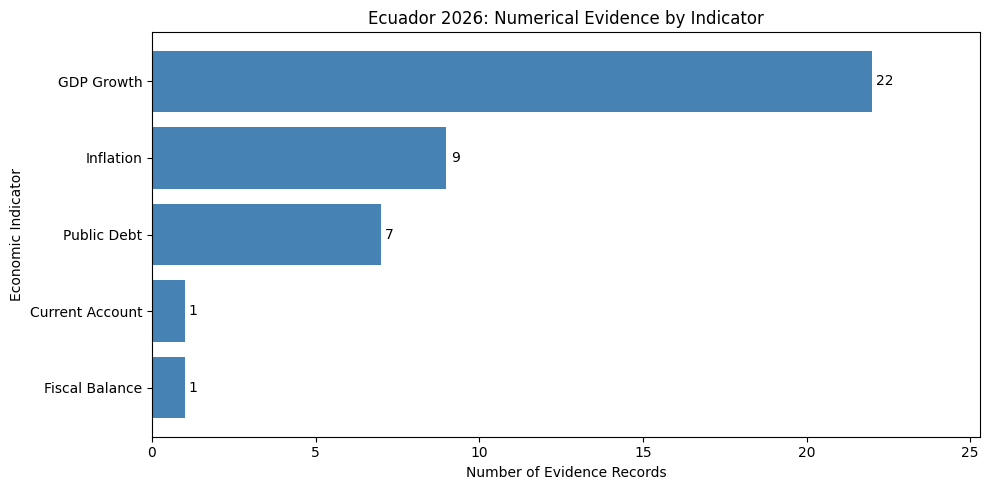

Chart saved successfully!


In [106]:

# Step 27: Economic indicator evidence chart

import matplotlib.pyplot as plt

indicator_counts = (
    evidence_df["Indicator"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 5))

bars = plt.barh(
    indicator_counts.index,
    indicator_counts.values,
    color="steelblue"
)

plt.bar_label(bars, padding=3)

plt.title("Ecuador 2026: Numerical Evidence by Indicator")
plt.xlabel("Number of Evidence Records")
plt.ylabel("Economic Indicator")

plt.xlim(0, indicator_counts.max() * 1.15)
plt.tight_layout()

plt.savefig(
    "ecuador_indicator_evidence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

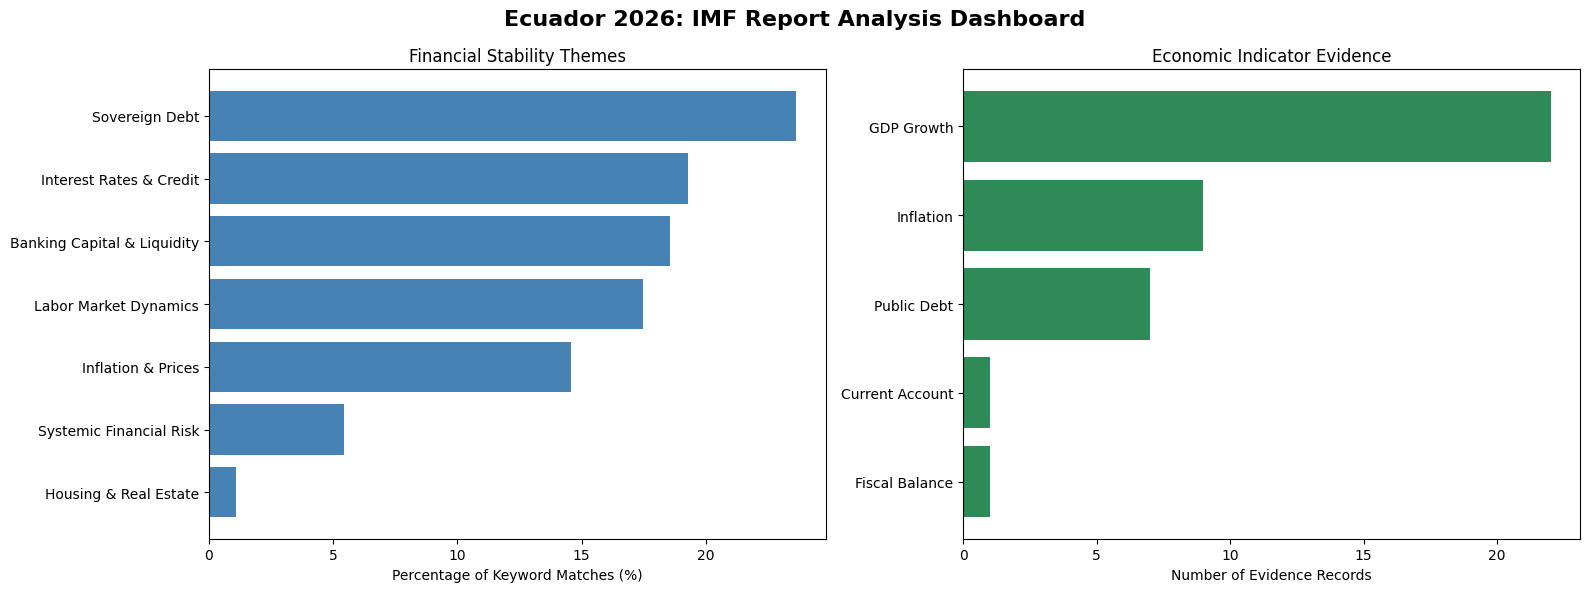

Dashboard saved successfully!


In [107]:

# Step 28: Combined Financial Analysis Dashboard

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Financial themes
axes[0].barh(
    theme_df["Theme"],
    theme_df["Percentage"],
    color="steelblue"
)

axes[0].invert_yaxis()
axes[0].set_title("Financial Stability Themes")
axes[0].set_xlabel("Percentage of Keyword Matches (%)")

# Chart 2: Numerical evidence
indicator_counts = (
    evidence_df["Indicator"]
    .value_counts()
    .sort_values()
)

axes[1].barh(
    indicator_counts.index,
    indicator_counts.values,
    color="seagreen"
)

axes[1].set_title("Economic Indicator Evidence")
axes[1].set_xlabel("Number of Evidence Records")

plt.suptitle(
    "Ecuador 2026: IMF Report Analysis Dashboard",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "ecuador_financial_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved successfully!")

# Completion of assignment requirements — RAG, structured extraction, evaluation and dashboard




In [108]:
# Step 29 — Install dense retrieval dependencies
!pip -q install sentence-transformers faiss-cpu pydantic
import os, json, time, re
import numpy as np
import pandas as pd
from pydantic import BaseModel, Field
from typing import Optional, List
from google.genai import types
MODEL_NAME = "gemini-3.5-flash-lite"  # Change if not listed for your API key
assert len(improved_chunks) > 0 and len(cleaned_pages) > 0


In [109]:
# Step 30 — Local dense RAG index (Sentence Transformers + FAISS)
from sentence_transformers import SentenceTransformer
import faiss
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
chunk_texts = [c["text"] for c in improved_chunks]
embeddings = embedding_model.encode(chunk_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
embeddings = np.asarray(embeddings, dtype="float32")
rag_index = faiss.IndexFlatL2(embeddings.shape[1])
rag_index.add(embeddings)
assert rag_index.ntotal == len(improved_chunks)
faiss.write_index(rag_index, "ecuador_faiss.index")
with open("ecuador_rag_metadata.json", "w") as f:
    json.dump([{k:c[k] for k in ("chunk_id", "start_page", "end_page", "token_count")} for c in improved_chunks], f, indent=2)
print("Indexed", rag_index.ntotal, "chunks")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Indexed 241 chunks


In [110]:
# Step 31 — Retrieve evidence with explicit source references
def retrieve_evidence(query, k=5):
    q = embedding_model.encode([query], normalize_embeddings=True).astype("float32")
    distances, ids = rag_index.search(q, min(k, rag_index.ntotal))
    return [{**improved_chunks[int(i)], "distance":float(d)} for d,i in zip(distances[0],ids[0]) if i >= 0]

def context_from_hits(hits):
    return "\n\n".join(f"[Chunk {h['chunk_id']}; PDF pages {h['start_page']}-{h['end_page']}]\n{h['text']}" for h in hits)

sample_question = "What does the IMF say about Ecuador banking liquidity, capital and nonperforming loans?"
sample_hits = retrieve_evidence(sample_question)
print([(h['chunk_id'],h['start_page'],h['end_page']) for h in sample_hits])


[(125, 45, 46), (112, 42, 43), (105, 41, 42), (60, 32, 33), (1, 1, 2)]


In [111]:
# Step 32 — RAG-grounded answer with abstention
class GroundedAnswer(BaseModel):
    answer: str
    cited_chunk_ids: List[int]
    insufficient_evidence: bool

def generate_rag_answer(question, k=5):
    hits = retrieve_evidence(question, k)
    prompt = f"""Answer the question ONLY from the retrieved IMF excerpts.
If not supported, say evidence is insufficient. Cite chunk IDs in the answer.
Never invent numerical values or dates.
QUESTION: {question}
EXCERPTS:\n{context_from_hits(hits)}"""
    response = client.models.generate_content(model=MODEL_NAME, contents=prompt,
        config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json", response_schema=GroundedAnswer))
    answer = GroundedAnswer.model_validate_json(response.text)
    valid_ids = {h['chunk_id'] for h in hits}
    assert set(answer.cited_chunk_ids).issubset(valid_ids), "Unretrieved citation supplied"
    return answer, hits

rag_questions = [
    "What are the IMF's banking-sector capital, liquidity and NPL findings?",
    "What are the main risks to fiscal sustainability and public debt?",
    "What assumptions and vulnerabilities does the IMF describe in its stress tests?",
    "What is the inflation outlook and what drives it?"
]
rag_results = []
for question in rag_questions:
    try:
        answer, hits = generate_rag_answer(question)
        rag_results.append({"question":question, **answer.model_dump(),
                            "retrieved_chunks":[{"chunk_id":h['chunk_id'], "start_page":h['start_page'], "end_page":h['end_page']} for h in hits]})
        print(question, "\n", answer.answer, "\n")
    except Exception as e:
        print("RAG answer failed:", question, str(e))
with open("ecuador_rag_answers.json", "w") as f: json.dump(rag_results,f,indent=2)


What are the IMF's banking-sector capital, liquidity and NPL findings? 
 The banking system's capital adequacy, measured by regulatory capital to risk-weighted assets, is reported across various periods (e.g., 16.7 in 2021, 17.3 in 2022, 15.8 in 2023, 15.7 in 2024, and 15.1 by Nov-25). Asset quality findings show nonperforming loans to total gross loans at 3.2 in 2021, 3.6 in 2022, 3.7 in 2023 and 2024, and 4.6 by Nov-25, alongside provisions to nonperforming loans figures such as 203.0 in 2021, 230.7 in 2022, 232.9 in 2023, 225.9 in 2024, and 185.9 by Nov-25. Liquidity findings include liquid assets to total assets at 16.4 in 2021, 23.6 in 2022, 20.7 in 2023, 18.3 in 2024, and 15.2 by Nov-25, and liquid assets to short-term liabilities at 35.5 in 2021, 48.1 in 2022, 36.9 in 2023, 34.4 in 2024, and 29.5 by Nov-25 [Chunk 124]. 

What are the main risks to fiscal sustainability and public debt? 
 Downside risks to the fiscal plan and debt outlook primarily stem from the uncertainty of ex

In [112]:
# Check retrieved source passages for the two answers
# that currently lack citations

questions_to_check = [
    "What assumptions and vulnerabilities does the IMF describe in its stress tests?",
    "What is the inflation outlook and what drives it?"
]

for question in questions_to_check:
    print("\n" + "=" * 70)
    print("QUESTION:", question)

    hits = retrieve_evidence(question, k=5)

    for hit in hits:
        print("\nChunk ID:", hit["chunk_id"])
        print("PDF pages:", hit["start_page"], "-", hit["end_page"])
        print("Source excerpt:")
        print(hit["text"][:1200])


QUESTION: What assumptions and vulnerabilities does the IMF describe in its stress tests?

Chunk ID: 162
PDF pages: 66 - 67
Source excerpt:
.3 Low Moderate Commentary: Medium‑term risk is assessed as moderate, reflecting uncertainty around the baseline, as indicated by the debt fanchart module and  potential downside risks. Stress test analysis shows that gross financing needs could increase substantially in the event of an unexpected natural disaster,  while the impact would be more limited following a commodity price decline.  Source: IMF staff estimates and projections. 0.4 0.5 0.2 0.1 0.5 0.1 25 50 Percentile in peer group 2/ 0 25 50 75 100 75 100 Value  (normalized) Triggered stress tests (stress tests not activated in gray)

2021 2023 2025 2027 2029 2031 5-25 pct 25-50 pct 50-75 pct 75-95 pct Actual

2021 2023 2025 2027 2029 2031 Financing provided by banks Actual Baseline Stress scenario 0.00 0.10 0.20 0.30 0.40 0.50 2023 2024 2025 2026 Medium-term index Low riskINTERNATIONAL M

In [114]:
# Step 33 — Strict schema, nullable indicators and source provenance
# Null is preferable to invented values; Ecuador is dollarized, so a conventional
# domestic central-bank policy rate may be inapplicable. Check the source.
class IndicatorValue(BaseModel):
    value: Optional[float] = None
    year: Optional[int] = None
    status: str = Field(description="historical, forecast, not_reported or not_applicable")
    evidence_quote: Optional[str] = None
    pdf_pages: List[int] = Field(default_factory=list)

class EcuadorIndicators(BaseModel):
    country_name: str
    gdp_growth_forecast_pct: IndicatorValue
    headline_inflation_rate_pct: IndicatorValue
    central_bank_policy_rate_pct: IndicatorValue
    non_performing_loan_ratio: IndicatorValue
    unemployment_rate_pct: IndicatorValue

indicator_queries = {
    "gdp_growth_forecast_pct":"real GDP growth forecast 2026 2027 projection",
    "headline_inflation_rate_pct":"headline inflation rate 2026 consumer price inflation annual percent",
    "central_bank_policy_rate_pct":"Ecuador central bank policy rate dollarization monetary policy",
    "non_performing_loan_ratio":"nonperforming loans ratio percent banking sector financial soundness",
    "unemployment_rate_pct":"unemployment rate 2025 2026 percent labor market"
}
indicator_hits = {key:retrieve_evidence(query, k=6) for key,query in indicator_queries.items()}
indicator_context = "\n\n".join(f"### {key}\n{context_from_hits(hits)}" for key,hits in indicator_hits.items())
indicator_prompt = f"""Extract Ecuador indicators using ONLY supplied IMF report excerpts.
For each field return a numeric value only if the exact measure, year, and percentage
are supported by a verbatim evidence_quote. Otherwise value=null, status=not_reported
or not_applicable, and quote=null. Do not conflate projected inflation with observed
inflation, credit growth with NPL, or lending rates with central-bank policy rates.
Use physical PDF page numbers in pdf_pages. Prefer 2026 forecasts for GDP and
clearly distinguish year/status for every field. Country name is Ecuador.
EXCERPTS:\n{indicator_context}"""
indicator_response = client.models.generate_content(model=MODEL_NAME,contents=indicator_prompt,
    config=types.GenerateContentConfig(temperature=0,response_mime_type="application/json",response_schema=EcuadorIndicators))
indicators = EcuadorIndicators.model_validate_json(indicator_response.text)
assert indicators.country_name.lower()=="ecuador"
# Basic evidence check: each claimed non-null number must carry a quote and a page.
for field in indicator_queries:
    v=getattr(indicators,field)
    if v.value is not None and (not v.evidence_quote or not v.pdf_pages):
        raise ValueError(f"Missing evidence for {field}")
with open("ecuador_core_indicators.json","w") as f:json.dump(indicators.model_dump(),f,indent=2)
print(json.dumps(indicators.model_dump(),indent=2))


{
  "country_name": "Ecuador",
  "gdp_growth_forecast_pct": {
    "value": 2.5,
    "year": 2026,
    "status": "forecast",
    "evidence_quote": "Real GDP is projected to expand by 2.5 percent in 2026 (up from 2.2 percent at the fourth review) and gradually rise to 3 percent over the medium term supported by the continued implementation of structural reforms.",
    "pdf_pages": [
      13
    ]
  },
  "headline_inflation_rate_pct": {
    "value": 3.0,
    "year": 2026,
    "status": "forecast",
    "evidence_quote": "Inflation, end of period (%) 1.9 3.0 1.6",
    "pdf_pages": [
      4
    ]
  },
  "central_bank_policy_rate_pct": {
    "value": null,
    "year": null,
    "status": "not_reported",
    "evidence_quote": null,
    "pdf_pages": []
  },
  "non_performing_loan_ratio": {
    "value": 4.0,
    "year": 2025,
    "status": "historical",
    "evidence_quote": "Nonperforming loans to total gross loans 3.2 3.6 3.7 3.7 4.6 4.4 4.0",
    "pdf_pages": [
      45
    ]
  },
  "unempl

In [115]:
# Step 34 — Extract 5–7 strengths and 5–7 vulnerabilities (or fewer if unsupported)
class RiskItem(BaseModel):
    finding: str
    evidence_quote: str
    pdf_pages: List[int]
class RiskAssessment(BaseModel):
    strengths: List[RiskItem]
    vulnerabilities: List[RiskItem]

risk_queries=["economic recovery growth drivers exports investment reserves Ecuador IMF",
              "banking capital liquidity credit financial resilience Ecuador IMF",
              "fiscal debt vulnerabilities oil price security risks IMF Ecuador",
              "cooperative banking risks fiscal adjustment downside risks Ecuador IMF"]
risk_hits={h['chunk_id']:h for q in risk_queries for h in retrieve_evidence(q,8)}
risk_prompt=f"""From the IMF excerpts, extract UP TO 7 strengths and UP TO 7 vulnerabilities.
Aim for 5-7 of each ONLY IF supported. Each finding must include a short verbatim
supporting quote and the physical PDF page numbers. No invented claims.
EXCERPTS:\n{context_from_hits(list(risk_hits.values()))}"""
risk_response=client.models.generate_content(model=MODEL_NAME,contents=risk_prompt,
    config=types.GenerateContentConfig(temperature=0,response_mime_type="application/json",response_schema=RiskAssessment))
risks=RiskAssessment.model_validate_json(risk_response.text)
with open("ecuador_qualitative_risks.json","w") as f:json.dump(risks.model_dump(),f,indent=2)
print("Strengths:",len(risks.strengths),"Vulnerabilities:",len(risks.vulnerabilities))


Strengths: 5 Vulnerabilities: 5


In [116]:
# Step 35 — Automated LLM-as-judge: extraction and RAG grounding
class AuditScore(BaseModel):
    factual_alignment: int = Field(ge=1,le=5)
    completeness: int = Field(ge=1,le=5)
    consistency: int = Field(ge=1,le=5)
    unsupported_claims: List[str]
    explanation: str

def audit_output(source, output, task):
    prompt=f"""Act as a strict independent auditor. Evaluate the OUTPUT only against SOURCE.
Score factual alignment, completeness and consistency from 1 (poor) to 5 (excellent).
Flag unsupported claims, missing evidence, numeric/date mismatches and wrong citations.
TASK: {task}\nSOURCE:\n{source}\nOUTPUT:\n{output}"""
    r=client.models.generate_content(model=MODEL_NAME,contents=prompt,
       config=types.GenerateContentConfig(temperature=0,response_mime_type="application/json",response_schema=AuditScore))
    return AuditScore.model_validate_json(r.text).model_dump()

audit_rows=[]
for result in rag_results:
    hits=[improved_chunks[next(i for i,c in enumerate(improved_chunks) if c['chunk_id']==h['chunk_id'])] for h in result['retrieved_chunks']]
    try:
        scores=audit_output(context_from_hits(hits),result['answer'],result['question'])
        audit_rows.append({"item":result['question'],"type":"RAG",**scores})
    except Exception as e:print("Audit failed:",e)
try:
    scores=audit_output(indicator_context,json.dumps(indicators.model_dump()),"Extract five macroeconomic indicators accurately")
    audit_rows.append({"item":"Indicator extraction","type":"JSON",**scores})
except Exception as e:print("Indicator audit failed:",e)
with open("ecuador_audit_scores.json","w") as f:json.dump(audit_rows,f,indent=2)
print(pd.DataFrame(audit_rows)[["item","factual_alignment","completeness","consistency"]].to_string(index=False) if audit_rows else "No audits completed")


Audit failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Indicator audit failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
                                                                           item  factual_alignment  completeness  consistency
         What are the IMF's banking-sector capital, liquidity and NPL findings?                  5             5            5
What assumptions and vulnerabilities does the IMF describe in its stress tests?                  5             3            5
                              What is the inflation outlook and what drives it?                  5             5            5


In [117]:
# Find IMF pages containing economic indicators

keywords = [
    "Selected Economic Indicators",
    "Real GDP growth",
    "Consumer prices",
    "Inflation"
]

for page_num, page_data in enumerate(pages):
    if isinstance(page_data, dict):
        text = page_data.get("text", "")
        pdf_page = page_data.get("page", page_num + 1)
    elif isinstance(page_data, str):
        text = page_data
        pdf_page = page_num + 1
    else:
        continue

    if any(keyword.lower() in text.lower() for keyword in keywords):
        print("\nPDF PAGE:", pdf_page)
        print(text[:4500])
        print("=" * 70)

In [118]:
# Search the original PDF for economic indicator tables
%pip install -q pymupdf
import fitz
import os

pdf_files = [
    f for f in os.listdir(".")
    if f.lower().endswith(".pdf")
]

print("Available PDFs:", pdf_files)

if pdf_files:
    doc = fitz.open(pdf_files[0])

    for i, page in enumerate(doc):
        text = page.get_text()

        if "selected economic indicators" in text.lower():
            print("\nPDF PAGE:", i + 1)
            print(text[:6000])
            print("=" * 70)

    doc.close()
else:
    print("Please upload the original IMF PDF.")

Available PDFs: ['1ecuea2026001-source-pdf.pdf']

PDF PAGE: 4
3 
 
Table 1. Ecuador: Selected Economic Indicators 
  
  
  
  
  
Projections 
  
  
  
2025 
  
2026 
  
2027 
  
  
  
  
  
  
  
  
Output 
  
  
  
  
  
  
  
Real GDP growth (%) 
  
  
3.7 
2.5 
 
2.5 
  
  
  
 
 
 
 
Prices 
  
  
 
 
 
 
Inflation, average (%)  
  
  
0.7 
2.9 
 
1.6 
Inflation, end of period (%)  
  
  
1.9 
 
3.0 
 
1.6 
  
  
  
 
 
 
 
Public sector 
  
  
 
 
 
 
Revenue (% GDP) 
  
  
35.5 
 
37.3 
 
36.3 
Expenditure (% GDP) 
  
  
38.4 
37.8 
 
35.6 
Overall fiscal balance (% GDP) 
  
  
-2.9 
 
-0.4 
 
0.7 
Primary balance (% GDP) 
  
  
-1.7 
 
0.9 
 
1.8 
Non-oil primary balance (incl. fuel subsidies) (% GDP) 
  
  
-5.1 
 
-3.3 
 
-1.7 
Public sector debt (% GDP) 
  
  
54.3 
 
52.7 
 
50.9 
 
 
 
 
 
 
 
 
Money and credit  
  
  
 
 
 
 
Broad money (% change) 1/ 
  
  
5.3 
 
4.4 
 
4.3 
Credit to the private sector (% change) 
  
  
9.8 
 
6.2 
 
4.4 
  
  
  
 
 
 
 
Balance of p

In [119]:

# Step 36 - Verified IMF economic time-series data
# Source: Ecuador IMF Country Report 2026, Table 1, PDF page 4

import pandas as pd

verified_temporal_records = []

imf_indicators = {
    "Real GDP Growth": [3.7, 2.5, 2.5],
    "Average Inflation": [0.7, 2.9, 1.6],
    "End-of-Period Inflation": [1.9, 3.0, 1.6],
    "Public Sector Debt": [54.3, 52.7, 50.9],
    "Private Sector Credit Growth": [9.8, 6.2, 4.4]
}

for indicator, values in imf_indicators.items():
    for year, value in zip([2025, 2026, 2027], values):
        verified_temporal_records.append({
            "Year": year,
            "Indicator": indicator,
            "Value": value,
            "Status": "Reported" if year == 2025 else "Projected",
            "PDF_Page": 4
        })

temporal_df = pd.DataFrame(verified_temporal_records)

temporal_df.to_csv(
    "ecuador_verified_temporal.csv",
    index=False
)

print("Verified temporal records:", len(temporal_df))
display(temporal_df)


Verified temporal records: 15


,Year,Indicator,Value,Status,PDF_Page
0,2025,Real GDP Growth,3.7,Reported,4
1,2026,Real GDP Growth,2.5,Projected,4
2,2027,Real GDP Growth,2.5,Projected,4
3,2025,Average Inflation,0.7,Reported,4
4,2026,Average Inflation,2.9,Projected,4
5,2027,Average Inflation,1.6,Projected,4
6,2025,End-of-Period Inflation,1.9,Reported,4
7,2026,End-of-Period Inflation,3.0,Projected,4
8,2027,End-of-Period Inflation,1.6,Projected,4
9,2025,Public Sector Debt,54.3,Reported,4


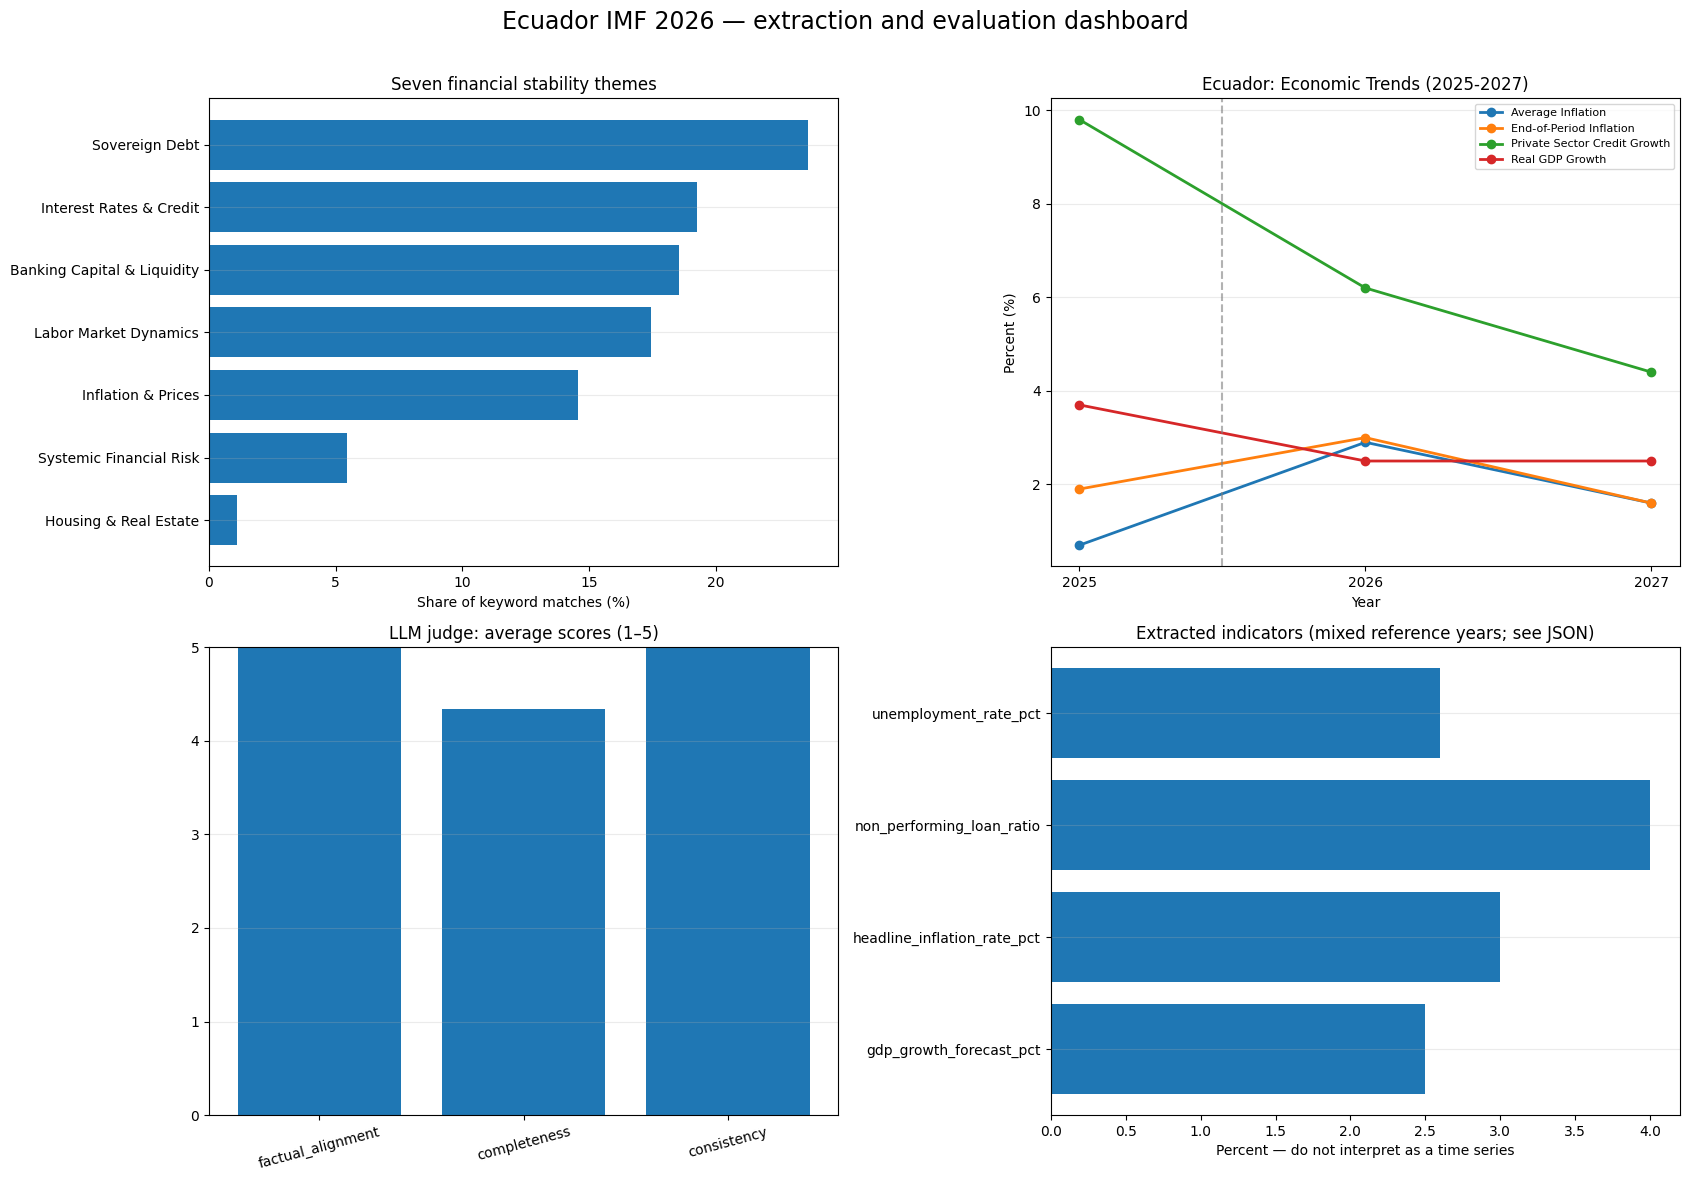

In [120]:
# Step 37 — Dashboard: four distinct plots and pd.melt, no fabricated data
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Convert wide indicator table to tidy long form with pd.melt.
wide = pd.DataFrame([{ "Country":"Ecuador", **{k:getattr(indicators,k).value for k in indicator_queries}}])
long_indicators = wide.melt(id_vars="Country",var_name="Indicator",value_name="Percent")
long_indicators.to_csv("ecuador_indicators_long.csv",index=False)

fig, axes=plt.subplots(2,2,figsize=(17,12))
# Plot 1 — 7 financial themes
plot_theme=theme_df.sort_values("Percentage")
axes[0,0].barh(plot_theme["Theme"],plot_theme["Percentage"])
axes[0,0].set_title("Seven financial stability themes")
axes[0,0].set_xlabel("Share of keyword matches (%)")
# Plot 2 - Verified IMF economic trends (2025-2027)
# Source: IMF Ecuador 2026, Table 1, PDF page 4

if not temporal_df.empty:

    # Keep related indicators on a comparable scale
    selected = [
        "Real GDP Growth",
        "Average Inflation",
        "End-of-Period Inflation",
        "Private Sector Credit Growth"
    ]

    plot_df = temporal_df[
        temporal_df["Indicator"].isin(selected)
    ]

    for label, group in plot_df.groupby("Indicator"):
        group = group.sort_values("Year")

        axes[0, 1].plot(
            group["Year"],
            group["Value"],
            marker="o",
            linewidth=2,
            label=label
        )

    axes[0, 1].set_xticks([2025, 2026, 2027])
    axes[0, 1].set_xlim(2024.9, 2027.1)

    # Mark beginning of projected period
    axes[0, 1].axvline(
        x=2025.5,
        linestyle="--",
        color="grey",
        alpha=0.6
    )

    axes[0, 1].legend(
        fontsize=8,
        loc="best"
    )

else:
    axes[0, 1].text(
        0.5, 0.5,
        "No verified temporal data available",
        ha="center",
        va="center",
        transform=axes[0, 1].transAxes
    )

axes[0, 1].set_title(
    "Ecuador: Economic Trends (2025-2027)"
)
axes[0, 1].set_xlabel("Year")
axes[0, 1].set_ylabel("Percent (%)")

# Plot 3 — LLM-as-judge diagnostics
score_df=pd.DataFrame(audit_rows)
if not score_df.empty:
    means=score_df[["factual_alignment","completeness","consistency"]].mean()
    axes[1,0].bar(means.index,means.values)
    axes[1,0].set_ylim(0,5);axes[1,0].tick_params(axis="x",rotation=15)
else:
    axes[1,0].text(.5,.5,"No completed evaluation scores",ha="center",va="center",transform=axes[1,0].transAxes)
axes[1,0].set_title("LLM judge: average scores (1–5)")
# Plot 4 — extracted core indicators, null values omitted
valid=long_indicators.dropna(subset=["Percent"])
if not valid.empty:
    axes[1,1].barh(valid["Indicator"],valid["Percent"])
else:
    axes[1,1].text(.5,.5,"No source-verified numeric indicators",ha="center",va="center",transform=axes[1,1].transAxes)
axes[1,1].set_title("Extracted indicators (mixed reference years; see JSON)")
axes[1,1].set_xlabel("Percent — do not interpret as a time series")
for ax in axes.flat:ax.grid(alpha=.25,axis="y")
fig.suptitle("Ecuador IMF 2026 — extraction and evaluation dashboard",fontsize=17)
fig.tight_layout(rect=[0,0,1,.97]);fig.savefig("ecuador_complete_dashboard.png",dpi=300,bbox_inches="tight")
plt.show()


In [121]:
# Step 38 — Provenance and coverage checklist
required_files=["ecuador_core_indicators.json","ecuador_qualitative_risks.json",
 "ecuador_rag_answers.json","ecuador_audit_scores.json","ecuador_complete_dashboard.png",
 "ecuador_indicators_long.csv","ecuador_verified_temporal.csv","ecuador_faiss.index"]
for name in required_files:print(("PASS" if os.path.exists(name) else "MISSING"),name)
print("\nRAG answered:",len(rag_results),"/",len(rag_questions))
print("Judged outputs:",len(audit_rows))
print("Verified time series records:",len(temporal_df),"(required for genuine longitudinal plot)")
print("Non-null indicator values:",sum(getattr(indicators,k).value is not None for k in indicator_queries))
print("NOTE: Confirm source quotes and page numbers manually before submission.")


PASS ecuador_core_indicators.json
PASS ecuador_qualitative_risks.json
PASS ecuador_rag_answers.json
PASS ecuador_audit_scores.json
PASS ecuador_complete_dashboard.png
PASS ecuador_indicators_long.csv
PASS ecuador_verified_temporal.csv
PASS ecuador_faiss.index

RAG answered: 4 / 4
Judged outputs: 3
Verified time series records: 15 (required for genuine longitudinal plot)
Non-null indicator values: 4
NOTE: Confirm source quotes and page numbers manually before submission.


In [122]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [123]:
# Step 39 — Package outputs; submit notebook LINK and written PDF separately
import zipfile
from google.colab import files
output_files=sorted(f for f in os.listdir(".") if f.startswith("ecuador_") and f.endswith((".csv",".json",".png",".txt",".index")))
zip_name="Ecuador_IMF_Analysis_Submission.zip"
with zipfile.ZipFile(zip_name,"w",zipfile.ZIP_DEFLATED) as z:
    for filename in output_files:z.write(filename)
print("ZIP:",zip_name,"| files:",len(output_files))
print("Remember: Canvas requires an executable Colab link or GitHub repository AND a separate 5–6 page PDF report.")
files.download(zip_name)


ZIP: Ecuador_IMF_Analysis_Submission.zip | files: 20
Remember: Canvas requires an executable Colab link or GitHub repository AND a separate 5–6 page PDF report.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>